# 06 — Hipótese: atrasos × avaliação ruim (e o frete junto)

**Hipótese da proposta:** a avaliação ruim está associada principalmente a atrasos na entrega, com duas origens possíveis:
- **Sellers** — postagem depois do prazo limite;
- **Logística** — entrega lenta/frete proporcionalmente caro em certas regiões (Norte/Nordeste).

**Como lemos os resultados:** tudo aqui é **associação observada**. Diferenças grandes e testes significativos mostram que as variáveis andam juntas, não que uma causa a outra (há confundidores possíveis: categoria, distância, época do ano, seller etc.).

Base: tabela `pedidos` (1 linha/pedido), apenas pedidos com avaliação válida no denominador das taxas de avaliação ruim.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import olist_utils as U

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid")

pedidos = U.load_processed("pedidos")
itens = U.load_processed("itens")
av = pedidos[pedidos["tem_avaliacao"]].copy()
av["ruim"] = av["avaliacao_ruim"].astype(bool).astype(int)
print("Pedidos com avaliação:", len(av))

Pedidos com avaliação: 74305


## 1. Avaliação ruim: entrega atrasada vs no prazo

In [2]:
def comparar(df, grupo, alvo="ruim", periodo="periodo_comparativo"):
    """Taxa do alvo por grupo, diferença em p.p., razão de taxas e qui-quadrado (por período)."""
    linhas = []
    for per, d in df.groupby(periodo):
        d = d[d[grupo] != "sem dado"]
        tab = d.groupby(grupo)[alvo].agg(["sum", "size"])
        tab["pct"] = tab["sum"] / tab["size"] * 100
        chi2, p, _, _ = chi2_contingency(np.c_[tab["sum"], tab["size"] - tab["sum"]])
        for g, r in tab.iterrows():
            linhas.append({"periodo_comparativo": per, "grupo": g, "numerador": int(r["sum"]),
                           "denominador": int(r["size"]), "pct": r["pct"], "qui2": chi2, "p_valor": p})
    return pd.DataFrame(linhas)

r_ent = comparar(av, "situacao_entrega")
r_ent.round(4)

,periodo_comparativo,grupo,numerador,denominador,pct,qui2,p_valor
0,2024 (proxy jan-ago/2017),entrega atrasada,427,740,57.7027,1790.8542,0.0
1,2024 (proxy jan-ago/2017),entrega no prazo,1885,21096,8.9353,1790.8542,0.0
2,2025 (proxy jan-ago/2018),entrega atrasada,2514,3994,62.9444,9166.9044,0.0
3,2025 (proxy jan-ago/2018),entrega no prazo,4501,48468,9.2865,9166.9044,0.0


In [3]:
def resumo_dif(r, a, b):
    p = r.pivot(index="periodo_comparativo", columns="grupo", values="pct")
    return pd.DataFrame({f"pct_{a}": p[a], f"pct_{b}": p[b], "diferenca_pp": p[a] - p[b], "razao": p[a] / p[b]}).round(2)

resumo_dif(r_ent, "entrega atrasada", "entrega no prazo")

,pct_entrega atrasada,pct_entrega no prazo,diferenca_pp,razao
periodo_comparativo,,,,
2024 (proxy jan-ago/2017),57.70,8.94,48.77,6.46
2025 (proxy jan-ago/2018),62.94,9.29,53.66,6.78


## 2. Avaliação ruim: postagem atrasada vs no prazo (seller)

In [4]:
r_post = comparar(av, "situacao_postagem")
display(r_post.round(4))
resumo_dif(r_post, "postagem atrasada", "postagem no prazo")

,periodo_comparativo,grupo,numerador,denominador,pct,qui2,p_valor
0,2024 (proxy jan-ago/2017),postagem atrasada,356,1865,19.0885,154.6614,0.0
1,2024 (proxy jan-ago/2017),postagem no prazo,1956,19971,9.7942,154.6614,0.0
2,2025 (proxy jan-ago/2018),postagem atrasada,1098,4470,24.5638,527.2985,0.0
3,2025 (proxy jan-ago/2018),postagem no prazo,5918,47998,12.3297,527.2985,0.0


,pct_postagem atrasada,pct_postagem no prazo,diferenca_pp,razao
periodo_comparativo,,,,
2024 (proxy jan-ago/2017),19.09,9.79,9.29,1.95
2025 (proxy jan-ago/2018),24.56,12.33,12.23,1.99


## 3. A postagem atrasada leva a mais entregas atrasadas ao cliente?
Frequência de entrega atrasada segundo a situação da postagem (base: todos os pedidos entregues com as datas necessárias).

In [5]:
ped_ok = pedidos[(pedidos["situacao_postagem"] != "sem dado") & (pedidos["situacao_entrega"] != "sem dado")].copy()
ped_ok["ent_atr"] = ped_ok["entrega_atrasada"].astype(bool).astype(int)
r_post_ent = comparar(ped_ok, "situacao_postagem", alvo="ent_atr")
display(r_post_ent.round(4))
resumo_dif(r_post_ent, "postagem atrasada", "postagem no prazo")

,periodo_comparativo,grupo,numerador,denominador,pct,qui2,p_valor
0,2024 (proxy jan-ago/2017),postagem atrasada,233,1894,12.3020,473.512,0.0
1,2024 (proxy jan-ago/2017),postagem no prazo,536,20103,2.6663,473.512,0.0
2,2025 (proxy jan-ago/2018),postagem atrasada,1010,4511,22.3897,1485.180,0.0
3,2025 (proxy jan-ago/2018),postagem no prazo,3068,48266,6.3564,1485.180,0.0


,pct_postagem atrasada,pct_postagem no prazo,diferenca_pp,razao
periodo_comparativo,,,,
2024 (proxy jan-ago/2017),12.30,2.67,9.64,4.61
2025 (proxy jan-ago/2018),22.39,6.36,16.03,3.52


## 4. Cruzamento 2×2: postagem × entrega → % avaliação ruim
Separa os efeitos: a entrega atrasada pesa mesmo quando o seller postou no prazo? A postagem atrasada pesa quando a entrega chega no prazo?

In [6]:
def cruz(df, by):
    g = df.groupby(by).agg(pedidos_com_avaliacao=("ruim", "size"), pedidos_avaliacao_ruim=("ruim", "sum")).reset_index()
    g["pct_avaliacao_ruim"] = U.pct(g["pedidos_avaliacao_ruim"], g["pedidos_com_avaliacao"])
    return g

av_ok = av[(av["situacao_postagem"] != "sem dado") & (av["situacao_entrega"] != "sem dado")]
c22 = cruz(av_ok, ["periodo_comparativo", "situacao_postagem", "situacao_entrega"])
c22["pct_dos_pedidos_avaliados_do_periodo"] = c22["pedidos_com_avaliacao"] / c22.groupby("periodo_comparativo")["pedidos_com_avaliacao"].transform("sum") * 100
c22.round(2)

,periodo_comparativo,situacao_postagem,situacao_entrega,pedidos_com_avaliacao,pedidos_avaliacao_ruim,pct_avaliacao_ruim,pct_dos_pedidos_avaliados_do_periodo
0,2024 (proxy jan-ago/2017),postagem atrasada,entrega atrasada,222,130,58.56,1.02
1,2024 (proxy jan-ago/2017),postagem atrasada,entrega no prazo,1643,226,13.76,7.52
2,2024 (proxy jan-ago/2017),postagem no prazo,entrega atrasada,518,297,57.34,2.37
3,2024 (proxy jan-ago/2017),postagem no prazo,entrega no prazo,19453,1659,8.53,89.09
4,2025 (proxy jan-ago/2018),postagem atrasada,entrega atrasada,989,627,63.40,1.89
5,2025 (proxy jan-ago/2018),postagem atrasada,entrega no prazo,3480,471,13.53,6.63
6,2025 (proxy jan-ago/2018),postagem no prazo,entrega atrasada,3005,1887,62.80,5.73
7,2025 (proxy jan-ago/2018),postagem no prazo,entrega no prazo,44988,4030,8.96,85.75


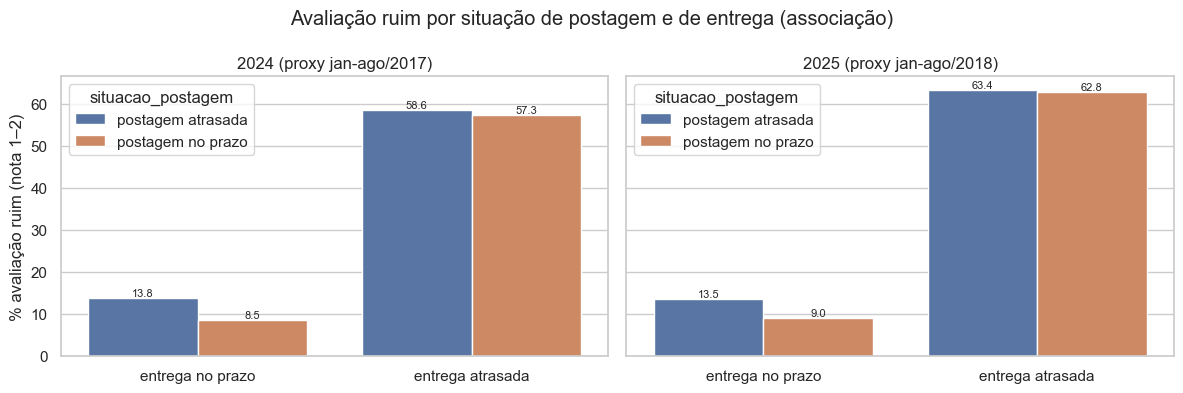

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (per, d) in zip(axes, c22.groupby("periodo_comparativo")):
    sns.barplot(data=d, x="situacao_entrega", y="pct_avaliacao_ruim", hue="situacao_postagem",
                order=["entrega no prazo", "entrega atrasada"], ax=ax)
    ax.set_title(per); ax.set_xlabel(""); ax.set_ylabel("% avaliação ruim (nota 1–2)")
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f", fontsize=8)
fig.suptitle("Avaliação ruim por situação de postagem e de entrega (associação)")
fig.tight_layout(); fig.savefig(U.FIG_DIR / "06_cruzamento_postagem_entrega.png", dpi=120)

## 5. Quanto da avaliação ruim está nos pedidos atrasados?
**Decomposição descritiva** (não é previsão causal): parcela dos pedidos ruins que estão em pedidos com entrega atrasada e, como referência de tamanho de oportunidade, qual seria o KPI1 **se** os pedidos atrasados tivessem a mesma taxa de avaliação ruim dos pedidos no prazo. Esse número é um teto otimista: assume que o atraso explica toda a diferença.

In [8]:
dec = []
for per, d in av[av["situacao_entrega"] != "sem dado"].groupby("periodo_comparativo"):
    atr = d[d["situacao_entrega"] == "entrega atrasada"]; ok = d[d["situacao_entrega"] == "entrega no prazo"]
    taxa_ok = ok["ruim"].mean()
    kpi_atual = d["ruim"].mean() * 100
    kpi_cenario = (ok["ruim"].sum() + len(atr) * taxa_ok) / len(d) * 100
    dec.append({"periodo_comparativo": per, "pct_pedidos_com_entrega_atrasada": len(atr) / len(d) * 100,
                "pct_dos_ruins_que_tiveram_entrega_atrasada": atr["ruim"].sum() / d["ruim"].sum() * 100,
                "kpi1_observado": kpi_atual, "kpi1_cenario_atrasados_com_taxa_do_prazo": kpi_cenario,
                "reducao_pp_teorica": kpi_atual - kpi_cenario})
dec = pd.DataFrame(dec)
dec.round(2)

,periodo_comparativo,pct_pedidos_com_entrega_atrasada,pct_dos_ruins_que_tiveram_entrega_atrasada,kpi1_observado,kpi1_cenario_atrasados_com_taxa_do_prazo,reducao_pp_teorica
0,2024 (proxy jan-ago/2017),3.39,18.47,10.59,8.94,1.65
1,2025 (proxy jan-ago/2018),7.61,35.84,13.37,9.29,4.09


In [9]:
# Mesmo exercício para a postagem do seller
dec_p = []
for per, d in av[av["situacao_postagem"] != "sem dado"].groupby("periodo_comparativo"):
    atr = d[d["situacao_postagem"] == "postagem atrasada"]; ok = d[d["situacao_postagem"] == "postagem no prazo"]
    kpi_atual = d["ruim"].mean() * 100
    kpi_cenario = (ok["ruim"].sum() + len(atr) * ok["ruim"].mean()) / len(d) * 100
    dec_p.append({"periodo_comparativo": per, "pct_pedidos_postagem_atrasada": len(atr) / len(d) * 100,
                  "pct_dos_ruins_com_postagem_atrasada": atr["ruim"].sum() / d["ruim"].sum() * 100,
                  "kpi1_observado": kpi_atual, "kpi1_cenario_postagem_atrasada_com_taxa_do_prazo": kpi_cenario,
                  "reducao_pp_teorica": kpi_atual - kpi_cenario})
dec_p = pd.DataFrame(dec_p)
dec_p.round(2)

,periodo_comparativo,pct_pedidos_postagem_atrasada,pct_dos_ruins_com_postagem_atrasada,kpi1_observado,kpi1_cenario_postagem_atrasada_com_taxa_do_prazo,reducao_pp_teorica
0,2024 (proxy jan-ago/2017),8.54,15.40,10.59,9.79,0.79
1,2025 (proxy jan-ago/2018),8.52,15.65,13.37,12.33,1.04


## 6. Origem do atraso por região: seller ou logística?
Se a entrega atrasa **mesmo quando o seller postou no prazo**, a explicação está mais do lado do transporte/destino. Comparamos, por região do cliente, a % de entrega atrasada entre pedidos com postagem no prazo, a % de postagem atrasada e o tempo mediano postagem→entrega.

In [10]:
reg = ped_ok.groupby(["periodo_comparativo", "regiao_cliente"]).apply(lambda d: pd.Series({
    "pedidos": len(d),
    "pct_postagem_atrasada": (d["situacao_postagem"] == "postagem atrasada").mean() * 100,
    "pct_entrega_atrasada": d["ent_atr"].mean() * 100,
    "pct_entrega_atrasada_dado_postagem_no_prazo": d.loc[d["situacao_postagem"] == "postagem no prazo", "ent_atr"].mean() * 100,
    "pct_entrega_atrasada_dado_postagem_atrasada": d.loc[d["situacao_postagem"] == "postagem atrasada", "ent_atr"].mean() * 100,
    "mediana_dias_postagem_entrega": d["dias_postagem_entrega"].median(),
    "mediana_dias_compra_entrega": d["dias_compra_entrega"].median(),
}), include_groups=False).reset_index()
reg.round(2)

,periodo_comparativo,regiao_cliente,pedidos,pct_postagem_atrasada,pct_entrega_atrasada,pct_entrega_atrasada_dado_postagem_no_prazo,pct_entrega_atrasada_dado_postagem_atrasada,mediana_dias_postagem_entrega,mediana_dias_compra_entrega
0,2024 (proxy jan-ago/2017),Centro-Oeste,1208.0,6.13,2.32,2.03,6.76,10.77,13.31
1,2024 (proxy jan-ago/2017),Nordeste,2210.0,8.37,7.69,6.72,18.38,14.02,17.25
2,2024 (proxy jan-ago/2017),Norte,521.0,8.06,3.45,2.92,9.52,14.03,17.06
3,2024 (proxy jan-ago/2017),Sudeste,14633.0,8.69,3.02,2.06,13.14,6.12,8.94
4,2024 (proxy jan-ago/2017),Sul,3425.0,9.40,3.24,2.84,7.14,8.17,11.84
5,2025 (proxy jan-ago/2018),Centro-Oeste,3113.0,7.97,7.93,6.60,23.39,9.92,13.02
6,2025 (proxy jan-ago/2018),Nordeste,4669.0,8.80,14.44,13.32,26.03,13.93,16.80
7,2025 (proxy jan-ago/2018),Norte,866.0,7.04,12.36,11.43,24.59,18.03,21.20
8,2025 (proxy jan-ago/2018),Sudeste,36797.0,8.73,6.95,5.46,22.50,5.37,8.04
9,2025 (proxy jan-ago/2018),Sul,7332.0,7.87,6.71,5.70,18.54,8.18,11.45


## 7. Frete junto: a restrição de custo
O frete é proporcionalmente mais caro onde a entrega é mais lenta? E pedidos atrasados pagaram frete diferente? Isso orienta se a solução logística pode ser "pagar mais caro" (o limite geral é 17,1%).

In [11]:
fr = U.kpi_frete(itens.assign(situacao_entrega=itens["entrega_atrasada"].map({True: "entrega atrasada", False: "entrega no prazo"}).fillna("sem dado")),
                 ["periodo_comparativo", "situacao_entrega"])
display(fr.round(2))
fr_reg = U.kpi_frete(itens, ["periodo_comparativo", "regiao_cliente"])
fr_reg = fr_reg.merge(reg[["periodo_comparativo", "regiao_cliente", "pct_entrega_atrasada", "mediana_dias_postagem_entrega"]],
                      on=["periodo_comparativo", "regiao_cliente"])
fr_reg.round(2)

,periodo_comparativo,situacao_entrega,itens,soma_frete,soma_preco_produtos,kpi2_pct_frete_sobre_produto
0,2024 (proxy jan-ago/2017),entrega atrasada,875,19277.96,130161.53,14.81
1,2024 (proxy jan-ago/2017),entrega no prazo,24067,460149.16,2863115.60,16.07
2,2024 (proxy jan-ago/2017),sem dado,1,15.00,179.00,8.38
3,2025 (proxy jan-ago/2018),entrega atrasada,4511,103276.16,599254.84,17.23
4,2025 (proxy jan-ago/2018),entrega no prazo,55807,1130086.28,6617917.40,17.08
5,2025 (proxy jan-ago/2018),sem dado,6,97.21,952.88,10.20


,periodo_comparativo,regiao_cliente,itens,soma_frete,soma_preco_produtos,kpi2_pct_frete_sobre_produto,pct_entrega_atrasada,mediana_dias_postagem_entrega
0,2024 (proxy jan-ago/2017),Centro-Oeste,1412,30448.34,198191.43,15.36,2.32,10.77
1,2024 (proxy jan-ago/2017),Nordeste,2453,72646.39,355197.69,20.45,7.69,14.02
2,2024 (proxy jan-ago/2017),Norte,587,19141.89,92768.73,20.63,3.45,14.03
3,2024 (proxy jan-ago/2017),Sudeste,16614,280183.64,1897225.55,14.77,3.02,6.12
4,2024 (proxy jan-ago/2017),Sul,3877,77021.86,450072.73,17.11,3.24,8.17
5,2025 (proxy jan-ago/2018),Centro-Oeste,3553,84964.16,451261.13,18.83,7.93,9.92
6,2025 (proxy jan-ago/2018),Nordeste,5174,178071.69,785140.40,22.68,14.44,13.93
7,2025 (proxy jan-ago/2018),Norte,977,38529.20,161528.92,23.85,12.36,18.03
8,2025 (proxy jan-ago/2018),Sudeste,42137,742730.75,4786465.60,15.52,6.95,5.37
9,2025 (proxy jan-ago/2018),Sul,8483,189163.85,1033729.07,18.30,6.71,8.18


## 8. Tabela de exportação `relacao_atraso_avaliacao.csv`
Uma linha por período × situação de postagem × situação de entrega, incluindo linhas de total (`todos`) para cada dimensão, com numeradores e denominadores.

In [12]:
base = av.copy()
partes = []
for pp in [True, False]:
    for ee in [True, False]:
        by = ["periodo_comparativo"] + (["situacao_postagem"] if pp else []) + (["situacao_entrega"] if ee else [])
        g = cruz(base, by)
        if not pp: g["situacao_postagem"] = "todos"
        if not ee: g["situacao_entrega"] = "todos"
        partes.append(g)
rel = pd.concat(partes, ignore_index=True)
# entrega atrasada por situação de postagem (todos os pedidos, não só avaliados)
ea = ped_ok.groupby(["periodo_comparativo", "situacao_postagem"]).agg(
    pedidos_entrega_avaliavel=("ent_atr", "size"), pedidos_entrega_atrasada=("ent_atr", "sum")).reset_index()
ea["pct_entrega_atrasada"] = U.pct(ea["pedidos_entrega_atrasada"], ea["pedidos_entrega_avaliavel"])
ea["situacao_entrega"] = "todos"
rel = rel.merge(ea, on=["periodo_comparativo", "situacao_postagem", "situacao_entrega"], how="left")
rel["granularidade"] = "periodo_situacao_postagem_situacao_entrega"
rel = rel.sort_values(["periodo_comparativo", "situacao_postagem", "situacao_entrega"]).reset_index(drop=True)

testes = pd.concat([r_ent.assign(comparacao="avaliacao_ruim_por_situacao_entrega"),
                    r_post.assign(comparacao="avaliacao_ruim_por_situacao_postagem"),
                    r_post_ent.assign(comparacao="entrega_atrasada_por_situacao_postagem")], ignore_index=True)
testes["granularidade"] = "periodo_comparacao_grupo"

U.export_csv(rel, "relacao_atraso_avaliacao")
U.export_csv(testes, "testes_associacao")
U.export_csv(reg.assign(granularidade="periodo_regiao_cliente"), "origem_atraso_regiao")
U.save_processed(dec, "decomposicao_entrega"); U.save_processed(dec_p, "decomposicao_postagem")
rel.round(2)

,periodo_comparativo,situacao_postagem,situacao_entrega,pedidos_com_avaliacao,pedidos_avaliacao_ruim,pct_avaliacao_ruim,pedidos_entrega_avaliavel,pedidos_entrega_atrasada,pct_entrega_atrasada,granularidade
0,2024 (proxy jan-ago/2017),postagem atrasada,entrega atrasada,222,130,58.56,NaN,NaN,NaN,periodo_situacao_postagem_situacao_entrega
1,2024 (proxy jan-ago/2017),postagem atrasada,entrega no prazo,1643,226,13.76,NaN,NaN,NaN,periodo_situacao_postagem_situacao_entrega
2,2024 (proxy jan-ago/2017),postagem atrasada,todos,1865,356,19.09,1894.0,233.0,12.30,periodo_situacao_postagem_situacao_entrega
3,2024 (proxy jan-ago/2017),postagem no prazo,entrega atrasada,518,297,57.34,NaN,NaN,NaN,periodo_situacao_postagem_situacao_entrega
4,2024 (proxy jan-ago/2017),postagem no prazo,entrega no prazo,19453,1659,8.53,NaN,NaN,NaN,periodo_situacao_postagem_situacao_entrega
5,2024 (proxy jan-ago/2017),postagem no prazo,todos,19971,1956,9.79,20103.0,536.0,2.67,periodo_situacao_postagem_situacao_entrega
6,2024 (proxy jan-ago/2017),sem dado,sem dado,1,0,0.00,NaN,NaN,NaN,periodo_situacao_postagem_situacao_entrega
7,2024 (proxy jan-ago/2017),sem dado,todos,1,0,0.00,NaN,NaN,NaN,periodo_situacao_postagem_situacao_entrega
8,2024 (proxy jan-ago/2017),todos,entrega atrasada,740,427,57.70,NaN,NaN,NaN,periodo_situacao_postagem_situacao_entrega
9,2024 (proxy jan-ago/2017),todos,entrega no prazo,21096,1885,8.94,NaN,NaN,NaN,periodo_situacao_postagem_situacao_entrega


## Leitura (evidência → interpretação)
Os números exatos estão nas tabelas acima e no README/relatório. A leitura geral é:
- **Evidência:** a taxa de avaliação ruim é muitas vezes maior nos pedidos com entrega atrasada do que nos entregues no prazo, nos dois períodos (p-valor ≈ 0 no qui-quadrado).
- **Evidência:** a postagem atrasada pelo seller também está associada a mais avaliação ruim e a mais entrega atrasada, mas a diferença é menor que a da entrega atrasada.
- **Interpretação:** a entrega atrasada ao cliente é o elo mais forte com a insatisfação; a postagem atrasada atua em parte *através* dela. A maior parte das entregas atrasadas ocorre com postagem no prazo, o que aponta também para o lado logístico/regional.
- **Limite:** associação ≠ causalidade; não controlamos categoria, distância ou seller simultaneamente.